# **Práctica 1**
## **Parte 1. Símplex combinado y L1-SVM**

Consiste en la programación de un script que resuelva un problema de programación lineal. Se puede introducir ya en forma matricial sin necesidad de ir capturando una por una las entradas, como si de un software comercial se tratase.

Se trata de programar el algoritmo **«Símplex completo»** visto en clase. Decidirá automáticamente si empezar con Símplex primal o dual y cambiará si fuera necesario. **No hace falta considerar casos degenerados.**

Además, genera un conjunto de datos que pertenezcan a **dos categorías linealmente separables**. Los datos deben estar en **dos dimensiones**. Plantea el problema de minimización del **L1-SVM**, formúlalo como problema dual y aplica el algoritmo que acabas de programar para resolverlo.

---
## **Solución:**

### Objetivo y alcance

Se implementa el **algoritmo Símplex combinado** de los apuntes de la asignatura. El procedimiento decide si puede comenzar con Símplex estándar o dual y conserva la base al cambiar de método. La aplicación del solucionador al **L1-SVM** se desarrolla y comprueba al final de este cuaderno.

Se admiten problemas de maximización o minimización con restricciones `<=` y `>=`, y variables originales no negativas. No se admiten igualdades directamente ni se garantiza el tratamiento general de la degeneración. La aplicación al L1-SVM introduce degeneración estructural; se explica y comprueba al final del cuaderno.

**Limitación:** si la tabla inicial no es primal ni dual factible, el algoritmo puede devolver `"no_resuelto"`. Este estado no equivale a infactibilidad. No se incluye una Fase I general ni una transformación automática del problema al dual de programación lineal.

### Entrada del algoritmo

Un problema de programación lineal se describe mediante:

$$
\operatorname{opt}_{x\geq 0}\; c^T x,
\qquad a_i^T x\;\mathrel{\square_i}\;b_i,\quad i=1,\ldots,m,
$$

donde cada $\square_i$ es $\leq$ o $\geq$.

La función principal recibe:

| Parámetro | Significado |
| --- | --- |
| `opt` | `"max"` o `"min"` |
| `c` | Vector de $n$ coeficientes del objetivo |
| `A` | Matriz de restricciones de tamaño $m\times n$ |
| `rest` | $m$ signos: `"<="` o `">="` |
| `b` | Vector de $m$ términos independientes |

Las variables auxiliares no se incluyen en la entrada. Por ejemplo:

$$
\begin{aligned}
\max\quad & 5x_1+4x_2\\
\text{s.a.}\quad &4x_1+2x_2\leq 8\\
&x_1+x_2\leq 3\\
&x_1,x_2\geq 0.
\end{aligned}
$$

En este caso, $c=(5,4)^T$, $A=\left(\begin{smallmatrix}4&2\\1&1\end{smallmatrix}\right)$, $b=(8,3)^T$ y `rest = ["<=", "<="]`.

### Diseño de la implementación y decisiones adoptadas

**`preprocesar()`** valida las dimensiones, los tipos de restricciones y los datos numéricos. Convierte cada desigualdad `>=` en `<=` multiplicando ambos miembros por $-1$. Después incorpora una variable auxiliar por restricción. Así se obtiene una matriz ampliada $\bar A=[\widetilde A\mid I_m]$ y el tableau inicial

$$
M_0=\begin{pmatrix}
1&-\bar c^T&0\\
0&\bar A&\widetilde b
\end{pmatrix},
\qquad\bar c=(c^T,0,\ldots,0)^T.
$$

**`actualizar_matriz()`** reconstruye la tabla de cada iteración desde la matriz de referencia, como se indica en los apuntes, en lugar de encadenar operaciones de fila sobre la tabla anterior. Sea $B$ la submatriz formada por las columnas **básicas de $\bar A$** y $c_B$ el vector de coeficientes del objetivo de esas variables. Entonces:

$$
M=\begin{pmatrix}
1&c_B^TB^{-1}\\
0&B^{-1}
\end{pmatrix}M_0.
$$

Se mantiene el cálculo explícito de $B^{-1}$ por **fidelidad al desarrollo matricial del curso**. Para aplicaciones grandes sería preferible resolver sistemas lineales sin formar la inversa explícitamente.

La lista `base` contiene **índices de columnas del tableau completo**, no índices relativos a $\bar A$: la columna 0 corresponde a $z$, las columnas $1,\ldots,n$ a las variables originales y las siguientes a las auxiliares. El orden de `base` corresponde al orden de las filas de restricciones.

**`simplex_estandar()`** requiere una base primal factible y trabaja con una función objetivo de maximización. Entra una variable no básica con coste reducido negativo; sale la básica que minimiza $b_i/a_{ie}$ entre los pivotes positivos. Se detiene en el óptimo o cuando detecta no acotación o alcanza el límite de iteraciones.

**`simplex_dual()`** requiere una tabla dual factible, en la convención de minimización empleada en clase (costes reducidos no positivos). Sale la variable básica cuyo término independiente es más negativo; entra la no básica que minimiza $|r_j/a_{sj}|$ entre las columnas con $a_{sj}<0$. Se detiene al recuperar la factibilidad primal o cuando detecta infactibilidad o alcanza el límite de iteraciones.

**`simplex_completo()`** coordina las dos variantes. Antes del estándar, prepara un objetivo de maximización; antes del dual, uno de minimización. Si el dual termina correctamente, conserva su base y reconstruye la tabla desde la matriz de referencia correspondiente a la maximización. Para interpretar el resultado solo recupera las variables originales; las no básicas valen cero y el signo del objetivo se restaura cuando el problema original era de minimización.

**Decisiones de alcance y estabilidad:** No se implementa el método de dos fases del Símplex, ya que el trabajo se limita al algoritmo combinado desarrollado en los apuntes. Las comprobaciones numéricas utilizan una tolerancia absoluta \(\varepsilon=10^{-9}\) para evitar que pequeños errores de redondeo provoquen decisiones incorrectas sobre factibilidad, optimalidad o pivotes. Además, se validan las dimensiones de entrada, se rechazan valores no finitos y se comprueba la validez de las bases utilizadas.

### Flujo de resolución

```mermaid
flowchart TD
    A["simplex_completo: problema original"] --> B["preprocesar: construir M0"]
    B --> C{"¿Base inicial primal factible?"}
    C -->|Sí| D["Preparar objetivo de maximización"]
    D --> E["simplex_estandar"]
    C -->|No| F["Preparar objetivo de minimización"]
    F --> G{"¿Tabla inicial dual factible?"}
    G -->|No| H["Devolver no_resuelto"]
    G -->|Sí| I["simplex_dual"]
    I --> J{"¿Estado óptimo?"}
    J -->|No| K["Devolver estado y última matriz"]
    J -->|Sí| L["Conservar base y preparar objetivo de maximización"]
    L --> E
    E --> M{"¿Estado óptimo?"}
    M -->|No| N["Devolver estado y última matriz"]
    M -->|Sí| O["Recuperar variables originales y objetivo"]
```

La transición del dual al estándar se realiza con la **misma base** y una nueva matriz de referencia. Ambos algoritmos utilizan `actualizar_matriz()`.

| Condición de arranque | Procedimiento |
| --- | --- |
| Base primal factible | Preparar maximización y ejecutar estándar |
| Base no primal factible, pero tabla dual factible | Ejecutar dual, conservar base y pasar a estándar |
| Ninguna de las dos condiciones | Devolver `"no_resuelto"` |

La tabla resume el diagrama también cuando el visor del notebook no renderiza Mermaid.


### Salida, estados y comprobación

La interfaz de `simplex_completo()` devuelve `(x, z, estado, M_f)`:

- `x`: valores de las variables **originales**, sin auxiliares.
- `z`: valor de la función objetivo en el problema original.
- `estado`: `"optimo"`, `"no acotado"`, `"infactible"`, `"max_iter"` o `"no_resuelto"`.
- `M_f`: última tabla calculada, útil para inspección y depuración.

Los valores `x` y `z` solo se presentan como óptimos si `estado == "optimo"`; en los demás casos ambos son `None`. `"no_resuelto"` indica que no se cumple ninguna condición de arranque implementada y **no** demuestra infactibilidad. `"max_iter"` indica un límite computacional, no una clasificación matemática del problema.

Se contrastan los resultados con problemas de solución conocida: estándar y dual, maximización y minimización, no acotación, infactibilidad y casos fuera del alcance de la tabla inicial. Además de comparar $x$ y $z$, se verificará que $c^Tx=z$ y que las restricciones originales se satisfacen dentro de la tolerancia numérica.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def actualizar_matriz(M0: np.ndarray, base: list):
    n_rest = M0.shape[0] - 1
    
    # Comprobamos que la base es correcta
    if len(base) != n_rest or len(set(base)) != n_rest:
        raise ValueError('La base debe contener una variable distinta por restricción.')
    if any(not isinstance(j, (int, np.integer)) or not 1 <= j < M0.shape[1] - 1 for j in base):
        raise ValueError('Los índices de la base deben señalar columnas de variables.')

    # Extraemos la matriz básica B usando los índices de la base en M0
    B = M0[1:, base]
    
    try:
        B_inv = np.linalg.inv(B)
    except np.linalg.LinAlgError as exc:
        raise ValueError('La matriz básica es singular.')
    
    # Coeficientes de las variables básicas en la función objetivo
    c_B = -M0[0, base]
    
    # Construimos la matriz de transformación T
    fila_T = np.hstack(([1], c_B @ B_inv))
    resto_T = np.hstack((np.zeros((n_rest, 1)), B_inv))
    T = np.vstack((fila_T, resto_T))
    
    # Calculamos la nueva matriz M
    M = T @ M0
    
    return M

In [3]:
def preprocesar(opt: str, c: np.ndarray, A: np.ndarray, rest: list[str], b: np.ndarray):
    # Convertimos datos numéricos
    try:
        c = np.asarray(c, dtype=float)
        A = np.asarray(A, dtype=float)
        b = np.asarray(b, dtype=float)
    except (TypeError, ValueError) as exc:
        raise ValueError('c, A y b deben contener valores numéricos.') from exc

    # Comprobamos que la entrada es válida
    if A.ndim != 2 or b.ndim != 1 or c.ndim != 1:
        raise ValueError("Dimensiones de la entrada incorrectas.")
    if opt not in ("max", "min"):
        raise ValueError("La optimización debe ser 'max' o 'min'.")
    if any(r not in ("<=", ">=") for r in rest):
        raise ValueError("Las restricciones deben ser '<=' o '>='.")
    if len(rest) != len(b) or len(b) != len(A):
        raise ValueError("El número de restricciones no coincide.")
    if len(c) != A.shape[1]:
        raise ValueError("El número de variables no coincide.")
    if len(c) == 0 or len(b) == 0:
        raise ValueError('Debe haber al menos una variable y una restricción.')
    if not (np.all(np.isfinite(c)) and np.all(np.isfinite(A)) and np.all(np.isfinite(b))):
        raise ValueError('Los datos no pueden contener NaN ni infinitos.')
    
    
    n_rest = len(rest)
    n_var = len(c)
    c_, A_, b_ = c.copy(), A.copy(), b.copy()
        
    # Convertimos todas las restricciones a '<='
    for i in range(n_rest):
        if rest[i] == ">=":
            A_[i] *= -1
            b_[i] *= -1
            
    # Añadimos variables de holgura
    I_n = np.eye(n_rest)
    A_ = np.hstack((A_, I_n))
    c_ = np.hstack((c_, np.zeros(n_rest)))
    
    # Calculamos la matriz inicial
    renglon_z = np.hstack(([1], -c_, [0]))
    restricciones = np.hstack((np.zeros((n_rest, 1)),
                               A_,
                               b_.reshape(-1, 1)
                               ))
    M0 = np.vstack((renglon_z, restricciones))
    
    return opt, M0

In [4]:
def simplex_estandar(M0: np.ndarray, base: list = None, 
                     max_iter: int = 1000, tol: float = 1e-9):
    estado = ''
    nf, nc = M0.shape
    n_rest = nf - 1
    n_var = nc - n_rest - 2
    
    # Si no definimos la base (iteración 0)
    if base is None:
        # Calculamos los índices (comenzamos en x=(0,...,0))
        base_ = [i for i in range(n_var+1, n_rest + n_var + 1)]
    else:
        base_ = base.copy()
    
    # Actualizamos la matriz
    M = actualizar_matriz(M0, base_)
    
    it = 0
    while it < max_iter:
        no_base = [i for i in range(1,nc-1) if i not in base_]
        
        # Calculamos la variable de entrada
        mas_neg = -tol
        ent = -1
        for i in no_base:
            actual = M[0, i]
            if actual < mas_neg:
                mas_neg = actual
                ent = i
                
        # Criterio de parada: no quedan coeficientes negativos en el renglón z
        if ent == -1:
            return M, base_, 'optimo'

        # Calculamos variable de salida
        menor = float('inf')
        for j in range(1, nf):
            if M[j, ent] <= tol:
                continue
            cociente = M[j, -1] / M[j, ent]
            if cociente < menor:
                menor = cociente
                sal = j
        
        if menor == float('inf'):
            estado = 'no acotado'
            return M, base_, estado
        
        # Sustituimos la variable básica de la fila de salida por la entrante
        base_[sal-1] = ent
        
        # Utilizamos la matriz original con la base modificada
        M = actualizar_matriz(M0, base_)
        
        it += 1
    
    # Comprobamos si el último pivote alcanzó el óptimo.
    if np.all(M[0, 1:-1] >= -tol):
        return M, base_, 'optimo'

    return M, base_, 'max_iter'

In [5]:
matriz, base, estado = simplex_estandar(np.array([
                            [1, -5, -4, 0, 0, 0], 
                            [0, 4, 2, 1, 0, 8], 
                            [0, 1, 1, 0, 1, 3]]))
print(matriz, base, estado)

[[ 1.   0.   0.   0.5  3.  13. ]
 [ 0.   1.   0.   0.5 -1.   1. ]
 [ 0.   0.   1.  -0.5  2.   2. ]] [1, 2] optimo


In [6]:
def simplex_dual(M0: np.ndarray, base: list = None, 
                 max_iter: int = 1000, tol: float = 1e-9):
    estado = ''
    nf, nc = M0.shape
    n_rest = nf - 1
    n_var = nc - n_rest - 2
    
    # Si no definimos la base (iteración 0)
    if base is None:
    # Calculamos los índices (comenzamos en x=(0,...,0))
        base_ = [i for i in range(n_var+1, n_rest + n_var + 1)]
    else:
        base_ = base.copy()
    
    # Actualizamos la matriz
    M = actualizar_matriz(M0, base_)
    
    it = 0
    while it < max_iter:
        no_base = [i for i in range(1,nc-1) if i not in base_]
        
        # Calculamos la variable de salida
        mas_neg = -tol
        sal = -1
        for i in range(1, nf):
            actual = M[i, -1]
            if actual < mas_neg:
                mas_neg = actual
                sal = i
                
        # Criterio de parada: no quedan términos independientes negativos
        if sal == -1:
            return M, base_, 'optimo'

        # Calculamos variable de entrada
        menor = float('inf')
        for j in no_base:
            if M[sal, j] >= -tol:
                continue
            cociente = np.abs(M[0, j] / M[sal, j])
            if cociente < menor:
                menor = cociente
                ent = j
        
        if menor == float('inf'):
            estado = 'infactible'
            return M, base_, estado
        
        # Modificamos la posición correspondiente a la fila de la matriz de entrada,
        # ajustando el índice
        base_[sal-1] = ent
        
        # Utilizamos la matriz original con la base modificada
        M = actualizar_matriz(M0, base_)
        
        it += 1
    
    # Comprobamos si el último pivote recuperó la factibilidad primal.
    if np.all(M[1:, -1] >= -tol):
        return M, base_, 'optimo'

    return M, base_, 'max_iter'

In [7]:
matriz, base, estado = simplex_dual(np.array([
                            [1, -8, -3, 0, 0, 0], 
                            [0, -4, -1, 1, 0, -5], 
                            [0, -2, -1, 0, 1, -4]]))
print(matriz, base, estado)

[[ 1.   0.   0.  -1.  -2.  13. ]
 [ 0.   1.   0.  -0.5  0.5  0.5]
 [ 0.   0.   1.   1.  -2.   3. ]] [1, 2] optimo


In [8]:
def simplex_completo(opt, c, A, rest, b, tol: float = 1e-9):
    opt_, M0 = preprocesar(opt, c, A, rest, b)
    # Trabajamos con una copia de M0
    M = M0.copy()
    
    # ¿Se cumple factibilidad primal?
    # Si sí, aplicamos estándar
    if np.all(M[1:, -1] >= -tol):
        # Queremos un problema de maximización
        if opt_ == "min":
            M[0, 1:] *= -1
            opt_ = "max"
        M1, base, estado = simplex_estandar(M, tol=tol)
    else: # Si no, cambiamos de max a min y aplicamos dual
        # Queremos un problema de minimización
        if opt_ == "max":
            M[0, 1:] *= -1
            opt_ = "min"
        if np.all(M[0, 1:-1] <= tol): # ¿Se cumple factibilidad dual?
            M, base, estado = simplex_dual(M, tol=tol)
            # Si el problema original era de minimización,
            # lo cambiamos a maximización para usar estándar
            if opt == "min":
                M0[0, 1:] *= -1
            # Pasamos a estándar si devuelve un resultado válido
            if estado == "optimo":
                M1, base, estado = simplex_estandar(M0, base, tol=tol)
            else:
                return None, None, estado, M
                
        else:
            return None, None, "no_resuelto", M
    
    # Si encontramos una solución óptima, interpretamos los resultados
    if estado == "optimo":
        x = np.zeros(len(c))
        for i, var_bas in enumerate(base):
            if var_bas <= len(c):
                x[var_bas-1] = M1[i+1, -1]

        z = M1[0, -1]
        if opt == "min":
            z *= -1
            
    else:
        return None, None, estado, M1
    
    return x, z, estado, M1

### Validación del algoritmo

Para comprobar el funcionamiento de la implementación se ha preparado una batería de pruebas que contempla problemas de maximización y minimización, el uso de los métodos Símplex primal y dual, distintas condiciones de terminación, tolerancias numéricas y validación de entradas.

**Uso de inteligencia artificial:** la batería de pruebas se ha elaborado con ayuda de ChatGPT (OpenAI, GPT-6). Su finalidad es contrastar los resultados obtenidos con soluciones conocidas y detectar posibles errores en la implementación.

Estas pruebas permiten verificar el comportamiento del algoritmo en los casos considerados, pero no constituyen una demostración de su corrección general.

In [9]:

import numpy as np

# Pruebas del Símplex completo
casos = [
    ("Máximo estándar", "max", [5, 4], [[4, 2], [1, 1]],
     ["<=", "<="], [8, 3], "optimo", [1, 2], 13),

    ("Mínimo estándar", "min", [-5, -4], [[4, 2], [1, 1]],
     ["<=", "<="], [8, 3], "optimo", [1, 2], -13),

    ("Máximo con varios pivotes", "max", [3, 2],
     [[1, 1], [1, 0], [0, 1]],
     ["<=", "<=", "<="], [4, 2, 3], "optimo", [2, 2], 10),

    ("Máximo con un pivote", "max", [1], [[1]],
     ["<="], [1], "optimo", [1], 1),

    ("Óptimo en el origen", "max", [-1], [[1]],
     ["<="], [2], "optimo", [0], 0),

    ("Mínimo con inicio dual", "min", [8, 3],
     [[4, 1], [2, 1]],
     [">=", ">="], [5, 4], "optimo", [0.5, 3], 13),

    ("Mínimo dual con restricciones mixtas", "min", [1],
     [[1], [1]], [">=", "<="], [1, 3], "optimo", [1], 1),

    ("Máximo con inicio dual", "max", [-1],
     [[1], [1]], [">=", "<="], [1, 3], "optimo", [1], -1),

    ("No acotado", "max", [1], [[-1]],
     ["<="], [1], "no acotado", None, None),

    ("Infactible", "max", [-1], [[1]],
     ["<="], [-1], "infactible", None, None),

    ("Sin factibilidad inicial primal ni dual (max)", "max", [1],
     [[1], [1]], [">=", "<="], [1, 3], "no_resuelto", None, None),

    ("Sin factibilidad inicial primal ni dual (min)", "min", [-1],
     [[1], [1]], [">=", "<="], [1, 3], "no_resuelto", None, None),
]

fallos = []
correctas = 0
atol = 1e-8


def comprobar(nombre, prueba):
    global correctas
    try:
        prueba()
        correctas += 1
        print(f"OK    {nombre}")
    except Exception as e:
        fallos.append((nombre, str(e)))
        print(f"FALLO {nombre}: {e}")


# 1. Resultados conocidos y condiciones de factibilidad
for nombre, opt, c, A, rest, b, esperado, x_esp, z_esp in casos:

    def prueba():
        c_, A_, b_ = map(
            lambda v: np.asarray(v, dtype=float), (c, A, b)
        )
        x, z, estado, M = simplex_completo(opt, c_, A_, rest, b_)

        assert estado == esperado, (
            f"Estado {estado!r}, esperado {esperado!r}"
        )
        assert isinstance(M, np.ndarray), "No se ha devuelto un tableau"

        if esperado == "optimo":
            assert x is not None and z is not None
            np.testing.assert_allclose(x, x_esp, atol=atol, rtol=0)
            np.testing.assert_allclose(z, z_esp, atol=atol, rtol=0)

            # No negatividad de las variables originales
            assert np.all(x >= -atol), "Variables originales negativas"

            # Cumplimiento de las restricciones originales
            lhs = A_ @ x
            for i, signo in enumerate(rest):
                if signo == "<=":
                    assert lhs[i] <= b_[i] + atol, (
                        f"Restricción {i+1} incumplida"
                    )
                else:
                    assert lhs[i] >= b_[i] - atol, (
                        f"Restricción {i+1} incumplida"
                    )

            # Coherencia del valor de la función objetivo
            np.testing.assert_allclose(z, c_ @ x, atol=atol, rtol=0)

        else:
            assert x is None and z is None, (
                "Se devolvió solución sin acreditar el óptimo"
            )

    comprobar(nombre, prueba)


# 2. Último pivote permitido: se alcanza el óptimo
def prueba_ultimo_pivote_estandar():
    _, M0 = preprocesar(
        "max", np.array([1.]), np.array([[1.]]),
        ["<="], np.array([1.])
    )
    M, base, estado = simplex_estandar(M0, max_iter=1)
    assert estado == "optimo", f"Estado obtenido: {estado}"
    np.testing.assert_allclose(M[0, -1], 1, atol=atol)


comprobar("Último pivote estándar: óptimo",
          prueba_ultimo_pivote_estandar)


def prueba_ultimo_pivote_dual():
    _, M0 = preprocesar(
        "min", np.array([1.]), np.array([[1.]]),
        [">="], np.array([1.])
    )
    M, base, estado = simplex_dual(M0, max_iter=1)
    assert estado == "optimo", f"Estado obtenido: {estado}"
    np.testing.assert_allclose(M[1, -1], 1, atol=atol)


comprobar("Último pivote dual: óptimo",
          prueba_ultimo_pivote_dual)


# 3. Límite de iteraciones realmente alcanzado
def prueba_limite_estandar():
    # Este problema necesita más de un pivote para alcanzar el óptimo.
    M0 = np.array([
        [1, -5, -4, 0, 0, 0],
        [0,  4,  2, 1, 0, 8],
        [0,  1,  1, 0, 1, 3]
    ], dtype=float)

    M, base, estado = simplex_estandar(M0, max_iter=1)
    assert estado == "max_iter", f"Estado obtenido: {estado}"
    assert np.any(M[0, 1:-1] < -1e-9), (
        "La tabla ya cumple la condición de optimalidad"
    )


comprobar("Límite estándar: max_iter", prueba_limite_estandar)


def prueba_limite_dual():
    # Este problema necesita más de un pivote para recuperar factibilidad.
    M0 = np.array([
        [1, -8, -3, 0, 0,  0],
        [0, -4, -1, 1, 0, -5],
        [0, -2, -1, 0, 1, -4]
    ], dtype=float)

    M, base, estado = simplex_dual(M0, max_iter=1)
    assert estado == "max_iter", f"Estado obtenido: {estado}"
    assert np.any(M[1:, -1] < -1e-9), (
        "La tabla ya cumple la condición de factibilidad primal"
    )


comprobar("Límite dual: max_iter", prueba_limite_dual)


# 4. Tolerancias numéricas
def prueba_tolerancia_estandar():
    M0 = np.array([
        [1., -1e-12, 0., 0.],
        [0., 1., 1., 1.]
    ])
    M, base, estado = simplex_estandar(M0)

    assert estado == "optimo"
    assert base == [2], "Se ha pivotado por un residuo numérico"


comprobar("Tolerancia estándar", prueba_tolerancia_estandar)


def prueba_tolerancia_dual():
    M0 = np.array([
        [1., -1., 0., 0.],
        [0., -1., 1., -1e-12]
    ])
    M, base, estado = simplex_dual(M0)

    assert estado == "optimo"
    assert base == [2], "Se ha pivotado por un residuo numérico"


comprobar("Tolerancia dual", prueba_tolerancia_dual)


# 5. Validación de entradas
def prueba_listas():
    x, z, estado, M = simplex_completo(
        "max", [1], [[1]], ["<="], [2]
    )
    assert estado == "optimo"
    np.testing.assert_allclose(x, [2], atol=atol)
    np.testing.assert_allclose(z, 2, atol=atol)


comprobar("Entrada mediante listas Python", prueba_listas)


entradas_invalidas = [
    ("Sentido inválido", "otro", [1], [[1]], ["<="], [2]),
    ("Restricción inválida", "max", [1], [[1]], ["="], [2]),
    ("Dimensión incorrecta", "max", [1, 2], [[1]], ["<="], [2]),
    ("NaN en coeficientes", "max", [np.nan], [[1]], ["<="], [2]),
    ("Infinito en restricciones", "max", [1], [[np.inf]], ["<="], [2]),
]

for nombre, opt, c, A, rest, b in entradas_invalidas:

    def prueba():
        try:
            simplex_completo(opt, c, A, rest, b)
        except (ValueError, TypeError):
            return
        raise AssertionError("La entrada inválida no fue rechazada")

    comprobar(nombre, prueba)


# 6. Validación de bases
_, M_base = preprocesar(
    "max",
    np.array([1., 1.]),
    np.array([[1., 0.], [2., 0.]]),
    ["<=", "<="],
    np.array([1., 2.])
)


def comprobar_base_invalida(nombre, base):
    def prueba():
        try:
            actualizar_matriz(M_base, base)
        except ValueError:
            return
        raise AssertionError("La base inválida no fue rechazada")

    comprobar(nombre, prueba)


# Dos índices repetidos no pueden formar una base válida
comprobar_base_invalida("Base con índices duplicados", [3, 3])

# El último índice corresponde al término independiente, no a una variable
comprobar_base_invalida(
    "Base con índice fuera de rango",
    [3, M_base.shape[1] - 1]
)

# Las columnas originales x1 y x2 forman una matriz singular
comprobar_base_invalida("Base singular", [1, 2])


# 7. Comprobación de que no se modifican las entradas originales
def prueba_sin_mutaciones():
    c = np.array([2., 3.])
    A = np.array([[1., 2.], [-2., 1.]])
    b = np.array([1., 2.])
    rest = [">=", "<="]

    c_original = c.copy()
    A_original = A.copy()
    b_original = b.copy()
    rest_original = rest.copy()

    preprocesar("min", c, A, rest, b)

    np.testing.assert_array_equal(c, c_original)
    np.testing.assert_array_equal(A, A_original)
    np.testing.assert_array_equal(b, b_original)
    assert rest == rest_original

    # Comprobamos también la función principal
    simplex_completo("min", c, A, rest, b)

    np.testing.assert_array_equal(c, c_original)
    np.testing.assert_array_equal(A, A_original)
    np.testing.assert_array_equal(b, b_original)
    assert rest == rest_original


comprobar("Conservación de los datos originales", prueba_sin_mutaciones)


# 8. Resumen
total = correctas + len(fallos)
print(f"\nRESULTADO: {correctas}/{total} comprobaciones superadas")

if fallos:
    print("\nComprobaciones pendientes:")
    for nombre, error in fallos:
        print(f" - {nombre}: {error}")
    raise AssertionError(f"{len(fallos)} comprobaciones fallidas")
else:
    print("Todas las comprobaciones han sido superadas.")


OK    Máximo estándar
OK    Mínimo estándar
OK    Máximo con varios pivotes
OK    Máximo con un pivote
OK    Óptimo en el origen
OK    Mínimo con inicio dual
OK    Mínimo dual con restricciones mixtas
OK    Máximo con inicio dual
OK    No acotado
OK    Infactible
OK    Sin factibilidad inicial primal ni dual (max)
OK    Sin factibilidad inicial primal ni dual (min)
OK    Último pivote estándar: óptimo
OK    Último pivote dual: óptimo
OK    Límite estándar: max_iter
OK    Límite dual: max_iter
OK    Tolerancia estándar
OK    Tolerancia dual
OK    Entrada mediante listas Python
OK    Sentido inválido
OK    Restricción inválida
OK    Dimensión incorrecta
OK    NaN en coeficientes
OK    Infinito en restricciones
OK    Base con índices duplicados
OK    Base con índice fuera de rango
OK    Base singular
OK    Conservación de los datos originales

RESULTADO: 28/28 comprobaciones superadas
Todas las comprobaciones han sido superadas.


---
### **Aplicación al L1-SVM**

#### Objetivo

Se aplica el Símplex combinado a un clasificador con regularización L1. El objetivo consiste en **generar un conjunto de datos en dos dimensiones con dos categorías linealmente separables**, **plantear el problema de minimización del L1-SVM**, **formularlo como problema dual** y **resolverlo con el algoritmo programado de Simplex**.

El procedimiento seguido es:

1. Generar los datos con una recta separadora conocida y una franja vacía alrededor de ella, de modo que la separabilidad lineal está garantizada por construcción.
2. Escribir el L1-SVM de los apuntes como problema de programación lineal en el formato de entrada del solucionador.
3. Obtener su dual mediante la tabla de correspondencias entre problema original y dual vista en clase.
4. Resolver el dual con `simplex_completo()` sin modificar ninguna de las funciones anteriores.
5. Recuperar el hiperplano separador $(w,b)$ a partir de la tabla final del dual y comprobar el resultado.

#### Generación de datos

In [10]:
def generar_datos(k: int = 40, separacion: float = 0.6, semilla: int = 0):
    if not isinstance(k, (int, np.integer)) or k < 2 or k % 2 != 0:
        raise ValueError('k debe ser un entero par mayor o igual que 2.')
    # Ambas clases deben tener una región de área positiva en [-4, 4]^2.
    limite = 12 / np.sqrt(5) - 0.5
    if not np.isfinite(separacion) or not 0 < separacion < limite:
        raise ValueError(f'La separación debe ser finita y estar entre 0 y {limite:.6f}.')

    rng = np.random.default_rng(semilla)

    # Recta separadora "real" a^T x + d = 0, con a unitario para que
    # a^T x + d sea la distancia con signo de x a la recta
    a = np.array([-1., 2.]) / np.sqrt(5)
    d = -0.5

    X, y = [], []
    n_clase = {1: 0, -1: 0}
    while len(X) < k:
        # Generamos un punto uniforme en el cuadrado [-4, 4]^2
        p = rng.uniform(-4, 4, size=2)
        dist = a @ p + d

        # Descartamos los puntos de la franja central: así las dos
        # clases quedan linealmente separables por construcción
        if abs(dist) < separacion:
            continue

        # Etiquetamos
        etiqueta = 1 if dist > 0 else -1
        if n_clase[etiqueta] >= k // 2:
            continue
        n_clase[etiqueta] += 1
        X.append(p)
        y.append(etiqueta)

    return np.array(X), np.array(y, dtype=float)

In [11]:
X, y = generar_datos(k=40, separacion=0.6, semilla=0)

print('Dimensiones de X:', X.shape)
print('Puntos de la clase +1:', int(np.sum(y == 1)))
print('Puntos de la clase -1:', int(np.sum(y == -1)))
print('Primeros puntos:\n', np.round(np.column_stack((X[:5], y[:5])), 3))

Dimensiones de X: (40, 2)
Puntos de la clase +1: 20
Puntos de la clase -1: 20
Primeros puntos:
 [[ 1.096 -1.842 -1.   ]
 [-3.672 -3.868 -1.   ]
 [ 2.506  3.302  1.   ]
 [ 0.853  1.836  1.   ]
 [ 0.349  3.481  1.   ]]


#### Problema de minimización (primal)

Sean $x_j=(x_{j1},\ldots,x_{jn})$, $j=1,\ldots,k$, los puntos (aquí $n=2$) e $y_j\in\{-1,1\}$ la variable que indica la clase de cada uno. El **L1-SVM** es

$$
\begin{aligned}
\arg\min_{w_i^+,w_i^-,b,\xi_j}\quad & \sum_i\frac{w_i^+}{2}+\sum_i\frac{w_i^-}{2}+c\sum_j\xi_j\\
\text{sujeto a}\quad & y_j\big((w^+-w^-)^T\cdot x_j+b\big)\geq 1-\xi_j\\
&\xi,\,w^+,\,w^-\geq 0
\end{aligned}
$$

donde se ha usado que $w_i=w_i^+-w_i^-$ y $|w_i|=w_i^++w_i^-$ en el óptimo.

El término independiente $b$ es una **variable no restringida**, y `simplex_completo()` solo admite variables no negativas. Para este caso, se generan dos variables $b^+\geq0$ y $b^-\geq0$ con $b=b^+-b^-$. El problema que se resuelve es entonces

$$
\begin{aligned}
\arg\min_{w_i^+,w_i^-,b^+,b^-,\xi_j}\quad & \sum_i\frac{w_i^+}{2}+\sum_i\frac{w_i^-}{2}+c\sum_j\xi_j\\
\text{sujeto a}\quad & y_j\big((w^+-w^-)^T\cdot x_j+b^+-b^-\big)+\xi_j\geq 1,\qquad j=1,\ldots,k\\
&\xi,\,w^+,\,w^-,\,b^+,\,b^-\geq 0.
\end{aligned}
$$

Para introducirlo en el solucionador se usa el formato de entrada descrito al principio (`opt`, `c`, `A`, `rest`, `b`), ordenando las variables como $(w^+,w^-,b^+,b^-,\xi)$:

- `opt = "min"` y `rest` contiene $k$ restricciones `">="` con término independiente $1$.
- `c` contiene $\frac12$ para cada $w_i^+$ y $w_i^-$, $0$ para $b^+$ y $b^-$, y $c$ para cada $\xi_j$.
- La fila $j$ de `A` es la restricción del punto $j$ desarrollada: $\big(y_jx_{j1},\ldots,y_jx_{jn},\;-y_jx_{j1},\ldots,-y_jx_{jn},\;y_j,\;-y_j,\;0,\ldots,1,\ldots,0\big)$, donde el $1$ ocupa la posición de $\xi_j$.

#### Formulación como problema dual

Se aplica la correspondencia de los apuntes entre problema original y dual: la minimización pasa a maximización, el lado derecho de las restricciones pasa a ser la función objetivo y viceversa, la matriz $A$ se traspone, cada restricción mayor o igual da lugar a una variable no negativa y cada variable no negativa a una restricción menor o igual. A la restricción del punto $j$ le corresponde una variable dual $\lambda_j\geq0$, y el problema dual queda

$$
\begin{aligned}
\arg\max_{\lambda_j}\quad & \sum_j\lambda_j\\
\text{sujeto a}\quad & \sum_j\lambda_jy_jx_{ji}\leq\frac12,\qquad i=1,\ldots,n\\
& -\sum_j\lambda_jy_jx_{ji}\leq\frac12,\qquad i=1,\ldots,n\\
& \sum_j\lambda_jy_j\leq0\\
& -\sum_j\lambda_jy_j\leq0\\
& \lambda_j\leq c,\qquad j=1,\ldots,k\\
& \lambda_j\geq0.
\end{aligned}
$$

Cada restricción del dual procede de una variable del primal:

| Variable primal | Restricción dual asociada |
| --- | --- |
| $w_i^+$ | $\sum_j\lambda_jy_jx_{ji}\leq\frac12$ |
| $w_i^-$ | $-\sum_j\lambda_jy_jx_{ji}\leq\frac12$ |
| $b^+$ | $\sum_j\lambda_jy_j\leq0$ |
| $b^-$ | $-\sum_j\lambda_jy_j\leq0$ |
| $\xi_j$ | $\lambda_j\leq c$ |

Las restricciones de $b^+$ y $b^-$ juntas equivalen a $\sum_j\lambda_jy_j=0$, ya que $b$ es una variable no restringida.

**Ventaja para el algoritmo.** Todas las restricciones del dual son `<=` con términos independientes $\frac12$, $0$ o $c$, es decir, no negativos. Por tanto, $\lambda=0$ está dentro de la región factible y `simplex_completo()` comienza directamente con el Símplex estándar. El primal también puede resolverse con el algoritmo, porque es de minimización con todos los coeficientes de la función objetivo no negativos: su tabla inicial es dual factible y empezaría con el Símplex dual. Esto se aprovecha en la validación como comprobación cruzada.

#### Recuperación del hiperplano desde la tabla final

Según los apuntes, el vector de valores óptimos de las variables duales del problema resuelto es $c_B^TB^{-1}$, donde $B$ es la matriz básica de la iteración final. En la matriz de Símplex, las columnas de las variables auxiliares forman la identidad y su coeficiente en la función objetivo es $0$, así que su entrada en el renglón de las $z$ vale

$$
c_B^TB^{-1}I-0=c_B^TB^{-1}.
$$

Como el dual del dual es el problema original, esas entradas son exactamente las variables del L1-SVM, en el mismo orden que las restricciones del dual:

$$
\big(w^+,\,w^-,\,b^+,\,b^-,\,\xi\big)=c_B^TB^{-1},
\qquad w=w^+-w^-,\qquad b=b^+-b^-.
$$

En la matriz Símplex, la columna $0$ es $z$, las columnas $1,\ldots,k$ son las $\lambda_j$ y las siguientes $2n+2+k$ son las auxiliares. Por eso basta leer `M_f[0, k+1 : k+1+m]` con $m=2n+2+k$.

In [12]:
def plantear_l1svm(X: np.ndarray, y: np.ndarray, c: float = 10.):
    if X.ndim != 2 or y.ndim != 1 or len(X) != len(y):
        raise ValueError('X debe ser k x n e y debe tener k etiquetas.')
    if not np.all(np.isin(y, (-1., 1.))):
        raise ValueError('Las etiquetas deben ser -1 o 1.')
    if not np.all(np.isfinite(X)) or not np.isfinite(c) or c <= 0:
        raise ValueError('X debe ser finita y c positivo.')

    k, n = X.shape

    # Coeficientes y_j x_ji de cada restricción
    yX = y.reshape(-1, 1) * X

    # Fila j: coeficientes de w+, w-, b+, b- y xi (violación del margen) en la restricción del punto j
    A = np.hstack((yX, -yX, y.reshape(-1, 1), -y.reshape(-1, 1), np.eye(k)))

    # Función objetivo: 1/2 para w+ y w-, 0 para b+ y b-, c para cada xi
    costes = np.hstack((np.full(2 * n, 0.5), [0., 0.], np.full(k, float(c))))

    # Restricciones y_j((w+ - w-)^T x_j + b+ - b-) + xi_j >= 1
    rest = ['>='] * k
    terminos = np.ones(k)

    return 'min', costes, A, rest, terminos


def formular_dual(opt: str, c: np.ndarray, A: np.ndarray, rest: list[str], b: np.ndarray):
    if opt != 'min' or any(r != '>=' for r in rest):
        raise ValueError('El problema original debe ser de minimización con restricciones ">=".')

    A = np.asarray(A, dtype=float)
    return 'max', np.asarray(b, dtype=float).copy(), A.T.copy(), ['<='] * A.shape[1], np.asarray(c, dtype=float).copy()


def recuperar_primal(M_f: np.ndarray, k: int, n: int):
    # Número de restricciones del dual (= número de variables del primal)
    m = 2 * n + 2 + k
    if M_f.shape != (m + 1, k + m + 2):
        raise ValueError('La tabla no corresponde a un dual de L1-SVM de ese tamaño.')
        
    # Vale con leer el renglón z para saber los valores de w, b y variables de violación del margen
    z = M_f[0, k + 1 : k + 1 + m].copy()
    # Deshacemos las descomposiciones en parte positiva y negativa
    w = z[:n] - z[n:2 * n]
    b = z[2 * n] - z[2 * n + 1]
    xi = z[2 * n + 2:] #variables de violación del margen

    return w, b, xi, z

#### Resolución

Se toma $c=10$. La formulación es de **margen blando**; la separabilidad por sí sola no garantiza $\xi=0$ para cualquier penalización. En esta muestra se comprueba que las violaciones del margen son nulas dentro de la tolerancia, por lo que la solución también resuelve el problema de margen duro. El dual se resuelve con la misma función `simplex_completo()` validada en el apartado anterior.

In [13]:
c_svm = 10
k, n = X.shape

# Planteamos el problema de minimización
opt_p, c_p, A_p, rest_p, b_p = plantear_l1svm(X, y, c_svm)

# Lo formulamos como problema dual
opt_d, c_d, A_d, rest_d, b_d = formular_dual(opt_p, c_p, A_p, rest_p, b_p)
print(f'Primal: {A_p.shape[1]} variables y {A_p.shape[0]} restricciones')
print(f'Dual:   {A_d.shape[1]} variables y {A_d.shape[0]} restricciones')

# Resolvemos el dual con el Símplex completo
lam, z_dual, estado, M_f = simplex_completo(opt_d, c_d, A_d, rest_d, b_d)
print('\nEstado:', estado)
if estado != 'optimo':
    raise RuntimeError(f'No se ha certificado el óptimo del dual: {estado}')
print(f'Valor óptimo del dual: {z_dual:.6f}')

# Recuperamos el hiperplano a partir de la tabla final
w, b, xi, v = recuperar_primal(M_f, k, n)
soportes = np.where(lam > 1e-8)[0]

print(f'\nw  = {np.round(w, 6)}')
print(f'b  = {b:.6f}')
print(f'||w||1 / 2 + c·Σξ = {c_p @ v:.6f}')
print(f'max ξ_j = {xi.max():.2e}')
print(f'\nVectores de soporte (λ_j > 0): {soportes.tolist()}')
for j in soportes:
    print(f'  punto {j:2d}: x = {np.round(X[j], 3)}, y = {int(y[j]):+d}, '
          f'λ = {lam[j]:.4f}, y(w^T x + b) = {y[j] * (X[j] @ w + b):.6f}')

Primal: 46 variables y 40 restricciones
Dual:   40 variables y 46 restricciones

Estado: optimo
Valor óptimo del dual: 0.610825

w  = [-0.296123  0.925527]
b  = -0.446624
||w||1 / 2 + c·Σξ = 0.610825
max ξ_j = 0.00e+00

Vectores de soporte (λ_j > 0): [3, 8, 34]
  punto  3: x = [0.853 1.836], y = +1, λ = 0.3054, y(w^T x + b) = 1.000000
  punto  8: x = [2.905 0.332], y = -1, λ = 0.2618, y(w^T x + b) = 1.000000
  punto 34: x = [-0.001 -0.598], y = -1, λ = 0.0436, y(w^T x + b) = 1.000000


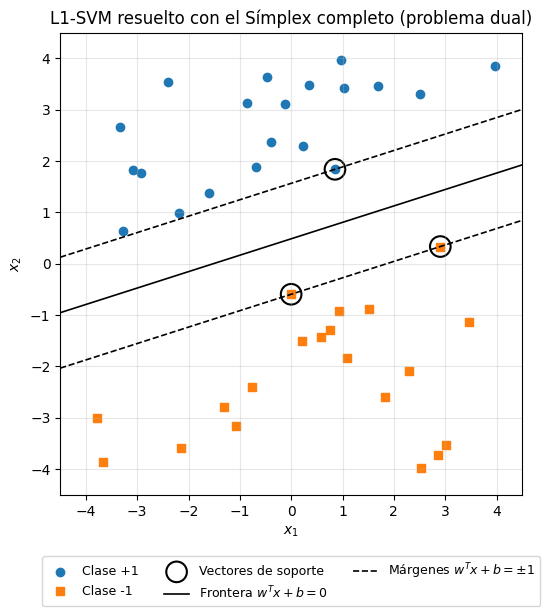

In [14]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(*X[y == 1].T, c='tab:blue', marker='o', label='Clase +1')
ax.scatter(*X[y == -1].T, c='tab:orange', marker='s', label='Clase -1')

ax.scatter(*X[soportes].T, s=220, facecolors='none', edgecolors='k',
           linewidths=1.5, label='Vectores de soporte')

x1 = np.linspace(-4.5, 4.5, 200)
for t, estilo, etiqueta in ((0, '-', 'Frontera $w^Tx+b=0$'),
                            (1, '--', 'Márgenes $w^Tx+b=\\pm1$'),
                            (-1, '--', None)):
    ax.plot(x1, (t - b - w[0] * x1) / w[1], 'k' + estilo, lw=1.2, label=etiqueta)

ax.set_xlim(-4.5, 4.5)
ax.set_ylim(-4.5, 4.5)
ax.set_aspect('equal')
ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.set_title('L1-SVM resuelto con el Símplex completo (problema dual)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=9)
ax.grid(alpha=0.3)
plt.show()

#### Interpretación de los resultados

- **Arranque del algoritmo.** El dual del L1-SVM tiene todas sus restricciones de tipo `<=` con términos independientes no negativos, así que `simplex_completo()` parte de una solución factible en el origen y aplica directamente el Símplex estándar. El primal, en cambio, arranca con el Símplex dual. Ambos caminos llevan al mismo valor óptimo.
- **Hiperplano.** El vector $(w,b)$ no se calcula aparte: se lee del renglón de las $z$ de la tabla final, en las columnas auxiliares ($c_B^TB^{-1}$). Así se ve en la práctica que lo que en un problema eran variables en el otro son restricciones.
- **Vectores de soporte.** En la ejecución mostrada solo **3 puntos** tienen $\lambda_j>0$. Todos cumplen $y_j(w^Tx_j+b)=1$, es decir, están sobre los hiperplanos de soporte, y los puntos con multiplicador nulo no contribuyen a esta representación del óptimo. Esto no implica que puedan eliminarse de cualquier problema modificado.
- **Hard-margin.** Con datos separables y $c=10$ se obtiene $\xi=0$: ningún punto queda dentro del margen y todos quedan bien clasificados.

#### Comprobación primal, dual y holgura complementaria

Se comprueban factibilidad, igualdad de objetivos y condiciones de complementariedad. Se resuelve además el primal con el Símplex combinado y se contrasta el valor con `scipy.optimize.linprog` (HiGHS), usado únicamente como referencia independiente.

**Degeneración estructural:** las dos desigualdades de $y^T\lambda=0$ tienen término independiente cero. La base inicial del dual es, por tanto, degenerada. Aunque el enunciado permite omitir estos casos, esta formulación los introduce: las pruebas verifican esta instancia, pero no garantizan ausencia de ciclos en general. Se mantiene la regla de pivote original y se deja esta limitación explícita para el feedback.

In [15]:
from scipy.optimize import linprog

# Factibilidad de la solución primal recuperada y de los multiplicadores duales.
atol_svm = 1e-7
np.testing.assert_array_less(-atol_svm, v)
assert np.all(A_p @ v >= b_p - atol_svm)
assert np.all(lam >= -atol_svm)
assert np.all(A_d @ lam <= b_d + atol_svm)
np.testing.assert_allclose(c_p @ v, z_dual, atol=atol_svm, rtol=0)
np.testing.assert_allclose(c_d @ lam, z_dual, atol=atol_svm, rtol=0)
np.testing.assert_allclose(lam * (A_p @ v - b_p), 0, atol=atol_svm)
np.testing.assert_allclose(v * (c_p - A_p.T @ lam), 0, atol=atol_svm)

# Dos caminos independientes: arranque dual del primal y referencia HiGHS.
v_primal, z_primal, estado_primal, _ = simplex_completo(opt_p, c_p, A_p, rest_p, b_p)
assert estado_primal == 'optimo'
assert np.all(v_primal >= -atol_svm)
assert np.all(A_p @ v_primal >= b_p - atol_svm)
np.testing.assert_allclose(z_primal, z_dual, atol=atol_svm, rtol=0)
referencia = linprog(c_p, A_ub=-A_p, b_ub=-b_p, bounds=(0, None), method='highs')
assert referencia.success, referencia.message
np.testing.assert_allclose(referencia.fun, z_dual, atol=atol_svm, rtol=0)

# El generador reproduce los datos y rechaza separaciones inviables o no finitas.
X_repetida, y_repetida = generar_datos(semilla=0)
np.testing.assert_array_equal(X, X_repetida)
np.testing.assert_array_equal(y, y_repetida)
for separacion_invalida in (0, -1, np.nan, np.inf, 5):
    try:
        generar_datos(separacion=separacion_invalida)
    except ValueError:
        pass
    else:
        raise AssertionError('El generador debe rechazar la separación inválida.')

assert np.all(y * (X @ w + b) >= 1 - atol_svm)
assert np.max(np.abs(xi)) <= atol_svm
print(f'Primal = dual = HiGHS: {z_dual:.9f}')
print(f'Brecha primal-dual: {abs(c_p @ v - z_dual):.3e}')
print('Factibilidad, complementariedad, margen y reproducibilidad: OK')

Primal = dual = HiGHS: 0.610824756
Brecha primal-dual: 0.000e+00
Factibilidad, complementariedad, margen y reproducibilidad: OK


### Estado de revisión y cuestiones para feedback

La ejecución del 15 de noviembre de 2026 supera **28/28 pruebas** del Símplex. El L1-SVM obtiene el mismo objetivo con el primal, el dual y HiGHS (**0,610824756**), y satisface las comprobaciones de factibilidad y complementariedad con tolerancia `1e-7`.

Se mantiene el algoritmo combinado del curso, sin método de dos fases ni garantía general de ausencia de ciclos. La representación de la igualdad del dual mediante dos desigualdades introduce una base inicial degenerada: la instancia incluida funciona, pero conviene confirmar si esta formulación es adecuada para el alcance de la práctica.

Los métodos de bajo nivel requieren las condiciones iniciales documentadas. La inversión explícita de la matriz básica y las tolerancias absolutas limitan la estabilidad ante problemas mal escalados.

La revisión conserva las funciones del Símplex. Se han añadido comprobaciones del L1-SVM y el rechazo de separaciones inviables del generador de datos, además de ajustes de explicación y presentación. Las versiones anteriores y sus resultados permanecen en el historial del repositorio.